# Step 3 - Threshold selection

Keep the fitted XGBoost model fixed and select the threshold with maximum validation F1. F2 and recall under a configurable precision constraint are alternative comparisons; no operational cost ratio or review-capacity constraint is assumed.

The current run selected 0.45939168334007263 with strict decision rule `score > threshold`. Validation precision was 0.754252, recall 0.599813 and F1 0.668226. Compared with the tuned model at 0.5, it caught 43 additional fraud cases and generated 58 additional false alarms on validation.

These are threshold-selection development metrics. AP and ROC AUC do not change when only the threshold changes. The model is not retrained and test data are not loaded.


**Run reference.** The narrative and displayed results refer to the current completed rerun used by `Evaluation.ipynb`. The earlier experiment is retained separately in `recorded_run/`. Its threshold and metrics must not be combined with the current artifacts.

**Reproduction.** Saved outputs can be reviewed without executing training. For a new full run, set `BT4012_TUNING_RUN` to the same new folder name before starting all four kernels. Outputs go to `reproductions/<name>/`; the committed artifacts are preserved. See this folder's README for commands and Colab configuration.


## 1. Paths and objective

Load the Step 2 artifacts and declare the threshold objective before inspecting its results. Available criteria are maximum F1, maximum F2, and maximum recall subject to a minimum precision requirement. The 70% precision floor is an illustrative comparison unless the constrained objective is selected.

Use the strict decision rule `score > threshold` throughout. The model scores are not assumed to be calibrated fraud probabilities.


In [1]:
# Optional only if missing; use the same package versions as Step 2.
# %pip install numpy pandas scikit-learn xgboost joblib matplotlib

from pathlib import Path
import copy
import gc
import hashlib
import importlib.metadata
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, confusion_matrix
from IPython.display import display

# Resolve the repository from the notebook working directory or BT4012_REPO_DIR.
import os
_start = Path(os.environ.get('BT4012_REPO_DIR', Path.cwd())).resolve()
REPO_DIR = next((p for p in (_start, *_start.parents)
                 if (p / 'Modelling.ipynb').is_file()
                 and (p / 'Fine_Tuning' / 'fine_tuning').is_dir()), None)
if REPO_DIR is None:
    raise FileNotFoundError('Open Jupyter within the repository, or set BT4012_REPO_DIR to its root.')
PROJECT_DIR = REPO_DIR / 'Fine_Tuning' / 'fine_tuning'

# Shared engineered CSVs; no symlinks are required. Root CSVs take precedence.
DATA_DIR = next((p for p in (REPO_DIR, REPO_DIR / 'data')
                 if all((p / f'{s}.csv').is_file() for s in ('train', 'val', 'test'))), REPO_DIR)

# Unset: inspect/use committed artifacts. Set a new name for a fresh reproduction.
RUN_NAME = os.environ.get('BT4012_TUNING_RUN', '').strip()
if RUN_NAME and (RUN_NAME in {'.', '..'} or '/' in RUN_NAME or '\\' in RUN_NAME):
    raise ValueError('BT4012_TUNING_RUN must be a single folder name.')
RUN_DIR = PROJECT_DIR / 'reproductions' / RUN_NAME if RUN_NAME else PROJECT_DIR
STEP2_DIR = RUN_DIR / 'step_2_outputs'
OUTPUT_DIR = RUN_DIR / 'step_3_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OBJECTIVE = 'f1'
MIN_PRECISION = 0.70
assert OBJECTIVE in {'f1', 'f2', 'recall_at_precision'}
assert 0 < MIN_PRECISION <= 1

def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, default=lambda v: v.item() if isinstance(v, np.generic) else str(v)), encoding='utf-8')

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

required = ['validation_scores.csv', 'selected_bundle.joblib', 'tuning_run.json']
for name in required:
    assert (STEP2_DIR / name).is_file(), f'Missing {name}. Complete Step 2, including its final save cell.'
run = json.loads((STEP2_DIR / 'tuning_run.json').read_text())
runtime_versions = {name: importlib.metadata.version(name) for name in
                    ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'joblib']}
different = {name: (run['versions'].get(name), version) for name, version in runtime_versions.items()
             if run['versions'].get(name) != version}
if different:
    raise RuntimeError(f'Use the Step 2 environment before loading its model. Version differences: {different}')

# Load the model artifact produced by Step 2.
bundle = joblib.load(STEP2_DIR / 'selected_bundle.joblib')
assert bundle['metadata']['selection'] == run['selection'], 'Bundle and tuning metadata differ.'
scores_path = STEP2_DIR / 'validation_scores.csv'
# Refuse changed inputs/objectives before writing any new result tables.
existing_selection = OUTPUT_DIR / 'threshold_selection.json'
if existing_selection.exists():
    previous = json.loads(existing_selection.read_text())
    expected = {'objective': OBJECTIVE,
                'minimum_precision': MIN_PRECISION if OBJECTIVE == 'recall_at_precision' else None,
                'source_model_sha256': sha256(STEP2_DIR / 'selected_bundle.joblib'),
                'source_scores_sha256': sha256(scores_path)}
    if any(previous.get(k) != v for k, v in expected.items()):
        raise RuntimeError('This output folder already contains a different selection. Choose a new OUTPUT_DIR before running.')
# XGBoost's saved probabilities were float32. Restore that dtype before promoting
# to float64; this preserves exact observed cutpoints instead of rounded CSV decimals.
saved = pd.read_csv(scores_path, dtype={'baseline_score': 'float32', 'selected_score': 'float32'})
assert {'TransactionID', 'isFraud', 'baseline_score', 'selected_score'}.issubset(saved.columns)
assert saved['TransactionID'].notna().all() and saved['TransactionID'].is_unique
assert saved['isFraud'].notna().all() and saved['isFraud'].isin([0, 1]).all()
y = saved['isFraud'].to_numpy(dtype=np.int64)
assert np.unique(y).tolist() == [0, 1]
baseline_scores = saved['baseline_score'].to_numpy(dtype=np.float64)
selected_scores = saved['selected_score'].to_numpy(dtype=np.float64)
for score in [baseline_scores, selected_scores]:
    assert np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
print('Selected candidate:', run['selection']['candidate_id'])
print('Validation rows:', len(y), '| fraud cases:', int(y.sum()))

Selected candidate: 15
Validation rows: 61196 | fraud cases: 2144


## 2. Validation-score verification

Verify the validation-file fingerprint and transaction order. Reproduce the selected model's scores once to confirm that the score file and fitted model match exactly, including values at decision cutpoints. This is inference only; test data are not read.


In [2]:
VAL_PATH = DATA_DIR / 'val.csv'
assert VAL_PATH.is_file(), f'Missing {VAL_PATH}'
audit = json.loads((RUN_DIR / 'baseline_outputs' / 'data_audit.json').read_text())
assert sha256(VAL_PATH) == audit['input_files']['val']['sha256'], 'Validation CSV changed since Step 1.'
raw_val = pd.read_csv(VAL_PATH, low_memory=False)
np.testing.assert_array_equal(raw_val['TransactionID'].to_numpy(), saved['TransactionID'].to_numpy())
np.testing.assert_array_equal(raw_val['isFraud'].to_numpy(), y)

def transform_rows(frame, fitted_bundle):
    X = frame.loc[:, fitted_bundle['features']].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    cats = fitted_bundle['categorical_columns']
    if cats:
        X[cats] = fitted_bundle['encoder'].transform(X[cats].astype(str))
    return X

probe_raw = raw_val.iloc[:1000].copy()
X_val = transform_rows(raw_val, bundle)
del raw_val
gc.collect()
reproduced = bundle['model'].predict_proba(X_val)[:, 1].astype(np.float64)
np.testing.assert_array_equal(reproduced, selected_scores,
    err_msg='Saved scores do not exactly reproduce. Rerun Step 2 save cell in its original environment before tuning.')
del X_val, reproduced
gc.collect()
np.testing.assert_allclose(average_precision_score(y, selected_scores),
    run['selected_validation_metrics']['Average precision'], atol=1e-10, rtol=0)
np.testing.assert_allclose(average_precision_score(y, baseline_scores),
    run['baseline_validation_metrics']['Average precision'], atol=1e-10, rtol=0)
print('Validation identity, model scores and saved AP values verified.')

Validation identity, model scores and saved AP values verified.


## 3. Threshold sweep

Evaluate the observed score cutpoints, threshold 0.5 and an endpoint that flags all rows. Keep tied scores together and use the strict `>` comparison. Report precision as zero when no rows are flagged. All sweep metrics use validation data.


In [3]:
def threshold_table(y_true, score, thresholds=None):
    y_true = np.asarray(y_true, dtype=np.int64)
    score = np.asarray(score, dtype=np.float64)
    assert y_true.ndim == score.ndim == 1 and len(y_true) == len(score) and len(score) > 0
    assert np.isin(y_true, [0, 1]).all() and 0 < y_true.sum() < len(y_true)
    assert np.isfinite(score).all()
    order = np.argsort(score, kind='stable')
    sorted_score = score[order]
    prefix_pos = np.r_[0, np.cumsum(y_true[order], dtype=np.int64)]
    if thresholds is None:
        thresholds = np.unique(np.r_[np.nextafter(sorted_score[0], -np.inf), sorted_score, 0.5])
    thresholds = np.asarray(thresholds, dtype=np.float64)
    assert np.isfinite(thresholds).all()
    excluded = np.searchsorted(sorted_score, thresholds, side='right')
    total_pos = int(y_true.sum())
    total_neg = len(y_true) - total_pos
    tp = total_pos - prefix_pos[excluded]
    alerts = len(y_true) - excluded
    fp = alerts - tp
    fn = total_pos - tp
    tn = total_neg - fp
    precision = np.divide(tp, alerts, out=np.zeros(len(tp), dtype=float), where=alerts > 0)
    recall = tp / total_pos
    return pd.DataFrame({'threshold': thresholds, 'precision': precision, 'recall': recall,
        'f1': 2 * tp / (2 * tp + fp + fn),
        'f2': 5 * tp / (5 * tp + fp + 4 * fn),
        'false_positive_rate': fp / total_neg,
        'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
        'alerts': alerts, 'alert_rate': alerts / len(y_true)})

sweep = threshold_table(y, selected_scores)
sweep.to_csv(OUTPUT_DIR / 'threshold_candidates.csv', index=False)
default_selected = threshold_table(y, selected_scores, [0.5]).iloc[0]
default_baseline = threshold_table(y, baseline_scores, [0.5]).iloc[0]
for result, reference in [(default_selected, run['selected_validation_metrics']),
                           (default_baseline, run['baseline_validation_metrics'])]:
    for column, original in [('precision', 'Precision'), ('recall', 'Recall'), ('f1', 'F1'),
                             ('tp', 'True positives'), ('fp', 'False positives'), ('fn', 'False negatives')]:
        np.testing.assert_allclose(result[column], reference[original], atol=1e-10, rtol=0)
print('Threshold cutpoints evaluated:', len(sweep))

Threshold cutpoints evaluated: 61044


## 4. Objective-based selection

Resolve exact objective ties by fewer false positives and then the higher threshold. A precision-constrained objective must meet its declared floor; an infeasible requirement raises an error. Alternative policies are reported separately from the chosen objective.


In [4]:
def choose_threshold(table, objective, min_precision=0.70):
    if objective == 'f1':
        metric, eligible = 'f1', table
    elif objective == 'f2':
        metric, eligible = 'f2', table
    elif objective == 'recall_at_precision':
        metric = 'recall'
        eligible = table[(table['precision'] >= min_precision) & (table['alerts'] > 0)]
    else:
        raise ValueError(f'Unknown objective: {objective}')
    if eligible.empty:
        return None
    return eligible.sort_values([metric, 'fp', 'threshold'], ascending=[False, True, False]).iloc[0]

chosen = choose_threshold(sweep, OBJECTIVE, MIN_PRECISION)
if chosen is None:
    raise ValueError('No threshold meets the requested precision floor. Review the requirement rather than silently weakening it.')
chosen_threshold = float(chosen['threshold'])
options = [('Step 1 baseline at 0.5', default_baseline),
           ('Step 2 selected model at 0.5', default_selected),
           ('Maximum F1', choose_threshold(sweep, 'f1')),
           ('Maximum F2', choose_threshold(sweep, 'f2')),
           (f'Max recall with precision >= {MIN_PRECISION:.0%}', choose_threshold(sweep, 'recall_at_precision', MIN_PRECISION))]
option_rows = []
for label, row in options:
    if row is not None:
        option_rows.append({'policy': label, 'status': 'available', **row.to_dict()})
    else:
        option_rows.append({'policy': label, 'status': 'no feasible threshold'})
policy_comparison = pd.DataFrame(option_rows)
policy_comparison.to_csv(OUTPUT_DIR / 'policy_comparison.csv', index=False)
display(policy_comparison)

comparison = pd.DataFrame([default_baseline, default_selected, chosen],
    index=['Step 1 baseline at 0.5', 'Step 2 selected model at 0.5', 'Step 3 chosen threshold'])
comparison['average_precision'] = [average_precision_score(y, baseline_scores),
    average_precision_score(y, selected_scores), average_precision_score(y, selected_scores)]
comparison['roc_auc'] = [roc_auc_score(y, baseline_scores), roc_auc_score(y, selected_scores), roc_auc_score(y, selected_scores)]
comparison.to_csv(OUTPUT_DIR / 'threshold_comparison.csv', index_label='stage')
display(comparison)
print('Declared objective:', OBJECTIVE)
print('Chosen threshold (full precision):', repr(chosen_threshold))
print(f'Compared with the tuned model at 0.5: TP change {int(chosen.tp-default_selected.tp):+d}; '
      f'FP change {int(chosen.fp-default_selected.fp):+d}; FN change {int(chosen.fn-default_selected.fn):+d}')
print('AP and ROC AUC are unchanged by the threshold choice.')

,policy,status,threshold,precision,recall,f1,f2,false_positive_rate,tp,fp,fn,tn,alerts,alert_rate
0,Step 1 baseline at 0.5,available,0.500000,0.740290,0.595616,0.660119,0.619843,0.007587,1277.0,448.0,867.0,58604.0,1725.0,0.028188
1,Step 2 selected model at 0.5,available,0.500000,0.774938,0.579757,0.663287,0.610511,0.006113,1243.0,361.0,901.0,58691.0,1604.0,0.026211
2,Maximum F1,available,0.459392,0.754252,0.599813,0.668226,0.625426,0.007095,1286.0,419.0,858.0,58633.0,1705.0,0.027861
3,Maximum F2,available,0.226163,0.524341,0.723414,0.607997,0.672360,0.023826,1551.0,1407.0,593.0,57645.0,2958.0,0.048336
4,Max recall with precision >= 70%,available,0.382396,0.700206,0.632929,0.664870,0.645330,0.009839,1357.0,581.0,787.0,58471.0,1938.0,0.031669


,threshold,precision,recall,f1,f2,false_positive_rate,tp,fp,fn,tn,alerts,alert_rate,average_precision,roc_auc
Step 1 baseline at 0.5,0.500000,0.740290,0.595616,0.660119,0.619843,0.007587,1277.0,448.0,867.0,58604.0,1725.0,0.028188,0.705831,0.947211
Step 2 selected model at 0.5,0.500000,0.774938,0.579757,0.663287,0.610511,0.006113,1243.0,361.0,901.0,58691.0,1604.0,0.026211,0.706608,0.951882
Step 3 chosen threshold,0.459392,0.754252,0.599813,0.668226,0.625426,0.007095,1286.0,419.0,858.0,58633.0,1705.0,0.027861,0.706608,0.951882


Declared objective: f1
Chosen threshold (full precision): 0.45939168334007263
Compared with the tuned model at 0.5: TP change +43; FP change +58; FN change -43
AP and ROC AUC are unchanged by the threshold choice.


## 5. Precision-recall trade-off

Plot precision, recall and F1 against threshold and mark the default and selected operating points on the precision-recall curve. Changing the threshold does not improve the underlying score ranking.


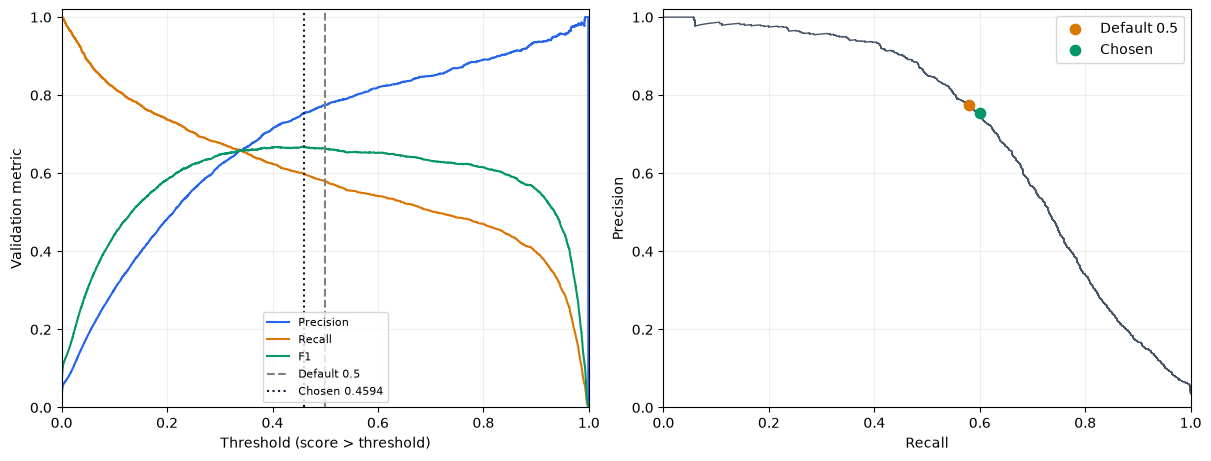

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for name, color in [('precision', '#2563eb'), ('recall', '#d97706'), ('f1', '#059669')]:
    axes[0].plot(sweep.threshold, sweep[name], label=name.title(), color=color, linewidth=1.5)
axes[0].axvline(0.5, color='gray', linestyle='--', label='Default 0.5')
axes[0].axvline(chosen_threshold, color='#111827', linestyle=':', label=f'Chosen {chosen_threshold:.4f}')
axes[0].set(xlabel='Threshold (score > threshold)', ylabel='Validation metric', xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(fontsize=8)
positive_alerts = sweep[sweep.alerts > 0].sort_values('recall')
axes[1].plot(positive_alerts.recall, positive_alerts.precision, color='#475569', linewidth=1)
for label, row, color in [('Default 0.5', default_selected, '#d97706'), ('Chosen', chosen, '#059669')]:
    axes[1].scatter(row.recall, row.precision, label=label, color=color, s=55, zorder=3)
axes[1].set(xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.02))
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.2)
fig.savefig(OUTPUT_DIR / 'threshold_tradeoff.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. Model and threshold export

Save the full-precision threshold with the unchanged model, encoder and feature order. Prediction requires `predict_proba` followed by the saved strict comparison; `model.predict()` retains the default decision rule.

Preserve Step 2 artifacts and write the new bundle to `step_3_outputs`. An existing different selection requires a separate output directory. Confirm that the reloaded bundle reproduces predictions.


In [6]:
selection = {'objective': OBJECTIVE, 'minimum_precision': MIN_PRECISION if OBJECTIVE == 'recall_at_precision' else None,
    'threshold': chosen_threshold, 'threshold_rule': '>',
    'tie_break': 'objective descending, false positives ascending, threshold descending',
    'validation_metrics': chosen.to_dict(),
    'average_precision': float(average_precision_score(y, selected_scores)),
    'roc_auc': float(roc_auc_score(y, selected_scores)),
    'candidate_id': run['selection']['candidate_id'],
    'source_model_sha256': sha256(STEP2_DIR / 'selected_bundle.joblib'),
    'source_scores_sha256': sha256(scores_path),
    'source_validation_sha256': audit['input_files']['val']['sha256'],
    'threshold_chosen_on_validation': True, 'test_performance_evaluated': False}
selection_path = OUTPUT_DIR / 'threshold_selection.json'
if selection_path.exists():
    old = json.loads(selection_path.read_text())
    for key in ['objective', 'minimum_precision', 'threshold', 'threshold_rule', 'source_model_sha256', 'source_scores_sha256']:
        if old.get(key) != selection[key]:
            raise RuntimeError('A different selection already exists in this folder. Choose a new OUTPUT_DIR and rerun to keep earlier results.')

final_bundle = dict(bundle)
final_bundle['metadata'] = copy.deepcopy(bundle['metadata'])
final_bundle.update(threshold=chosen_threshold, threshold_rule='>')
final_bundle['metadata'].update(threshold=chosen_threshold, threshold_rule='score > threshold', threshold_tuning=selection)
out_bundle = OUTPUT_DIR / 'threshold_tuned_bundle.joblib'
joblib.dump(final_bundle, out_bundle, compress=3)
save_json(selection_path, selection)

def predict_with_threshold(frame, fitted_bundle):
    X = transform_rows(frame, fitted_bundle)
    score = fitted_bundle['model'].predict_proba(X)[:, 1].astype(np.float64)
    assert fitted_bundle['threshold_rule'] == '>'
    prediction = (score > float(fitted_bundle['threshold'])).astype(np.int8)
    return score, prediction

loaded = joblib.load(out_bundle)
probe_scores, probe_predictions = predict_with_threshold(probe_raw, loaded)
np.testing.assert_array_equal(probe_scores, selected_scores[:len(probe_raw)])
np.testing.assert_array_equal(probe_predictions, (selected_scores[:len(probe_raw)] > chosen_threshold).astype(np.int8))
selected_predictions = (selected_scores > chosen_threshold).astype(np.int8)
tn, fp, fn, tp = confusion_matrix(y, selected_predictions, labels=[0, 1]).ravel()
np.testing.assert_array_equal([tp, fp, fn, tn], chosen[['tp', 'fp', 'fn', 'tn']].to_numpy(dtype=int))
pd.DataFrame({'TransactionID': saved['TransactionID'], 'isFraud': y,
              'selected_score': selected_scores, 'prediction': selected_predictions}).to_csv(
                  OUTPUT_DIR / 'threshold_validation_predictions.csv', index=False)
print('Saved model + threshold reload check passed. No model retraining or test evaluation occurred.')
print('Threshold comparison and selection saved.')

Saved model + threshold reload check passed. No model retraining or test evaluation occurred.
Threshold comparison and selection saved.
